# 04 - Deployment and Monitoring

Uses the saved model bundle exactly as the Streamlit app does. Run `python -m product_discontinuation.monitor` to produce the batch monitoring outputs referenced at the end.

**All probabilities in this notebook are calibrated** (model version 1.1.0, Platt scaling), matching the app, unless a cell says otherwise. The risk thresholds are calibrated: High from 0.283 and Medium from 0.144.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from product_discontinuation import config

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
from product_discontinuation.persistence import load_bundle, model_paths
from product_discontinuation.predict import predict_weekly, explain_prediction
from product_discontinuation import monitoring

bundle = load_bundle(model_paths(config.PRIMARY_HORIZON)[0])
weekly = pd.read_parquet(config.PROCESSED_DIR / "app_weekly.parquet")
history = pd.read_parquet(config.PROCESSED_DIR / "edition_history.parquet")
{k: bundle[k] for k in ["model_name", "model_version", "horizon", "threshold", "raw_threshold", "risk_medium_floor", "calibrator", "trained_at", "sklearn_version"]}

{'model_name': 'hist_gradient_boosting',
 'model_version': '1.1.0',
 'horizon': 13,
 'threshold': 0.2825334577996326,
 'raw_threshold': 0.1030733023493059,
 'risk_medium_floor': 0.1438551611639104,
 'calibrator': {'method': 'platt',
  'a': 0.9011334166857777,
  'b': 1.0177032058024367},
 'trained_at': '2026-11-06T11:06:24+00:00',
 'sklearn_version': '1.7.2'}

## 1. Validate and score the live edition (94)

The table below shows the ten highest-risk products by design. It is not typical of the edition: see the summary after it.

In [2]:
live = weekly[weekly.CatEdition.isin(config.CENSORED_EDITIONS)].drop(columns=[config.TARGET])
print(monitoring.validate_scoring_input(live))
live_features, live_preds = predict_weekly(bundle, live, history=history)
live_preds.sort_values("probability", ascending=False).head(10)

{'rows': 331397, 'products': 29693, 'product_editions': 29693, 'editions': [94], 'zero_price_rows': 577, 'zero_actuals_rows': 16446, 'groups_with_week_gaps': 1557}


,CatEdition,ProductKey,probability,predicted_discontinued,risk_category
18959,94,70394,0.978599,1,High
19238,94,55779,0.976365,1,High
20831,94,34819,0.975401,1,High
20664,94,36941,0.974682,1,High
18754,94,45833,0.974682,1,High
20789,94,80210,0.974419,1,High
19473,94,77267,0.974419,1,High
18206,94,65740,0.974375,1,High
18949,94,8530,0.974370,1,High
17917,94,29475,0.974109,1,High


In [3]:
monitoring.prediction_summary(live_preds)

{'n_predictions': 28101,
 'mean_probability': 0.3315549138043868,
 'predicted_positive_rate': 0.4114088466602612,
 'share_high_risk': 0.4114088466602612,
 'share_medium_risk': 0.2054375289135618,
 'share_low_risk': 0.383153624426177}

## 2. Explaining one prediction with SHAP

SHAP is an explanation layer: it reads the model's outputs and changes no prediction, threshold or evaluation result. `shap.PermutationExplainer` is applied to the complete fitted pipeline over its 20 original inputs, with a fixed background of 200 rows sampled from development editions 89-92, stratified by edition and outcome. The explained quantity is the **calibrated** log-odds of `DiscontinuedTF = 1`, so the contributions plus the base value reproduce the calibrated probability shown in the app exactly.

Run `python -m product_discontinuation.shap_analysis` once to create the background and the evidence files read below.

In [4]:
from product_discontinuation.explain import LocalExplainer, load_background, waterfall_figure

explainer = LocalExplainer(bundle, load_background(config.PRIMARY_HORIZON))
top = live_preds.sort_values("probability", ascending=False).iloc[0]
row = live_features[live_features.ProductKey == top.ProductKey]
explanation = explainer.explain(row)
print(f"Calibrated probability {explanation.probability:.4f} | base (calibrated log-odds) {explanation.base_value:.4f} | calibrated log-odds {explanation.log_odds:.4f}")
explanation.contributions.head(8)

/opt/miniconda3/envs/ml_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Calibrated probability 0.9786 | base (calibrated log-odds) 0.0456 | calibrated log-odds 3.8227


,feature,value,contribution
0,log_forecast,0.07325,1.373642
1,log_actuals,0.605954,0.709315
2,previous_discontinued,1.0,0.457739
3,Supplier,13194,0.329489
4,HierarchyLevel2,28611,0.234926
5,prior_editions,1.0,0.185456
6,weeks_in_edition,7,0.138797
7,log_price,2.197225,0.114597


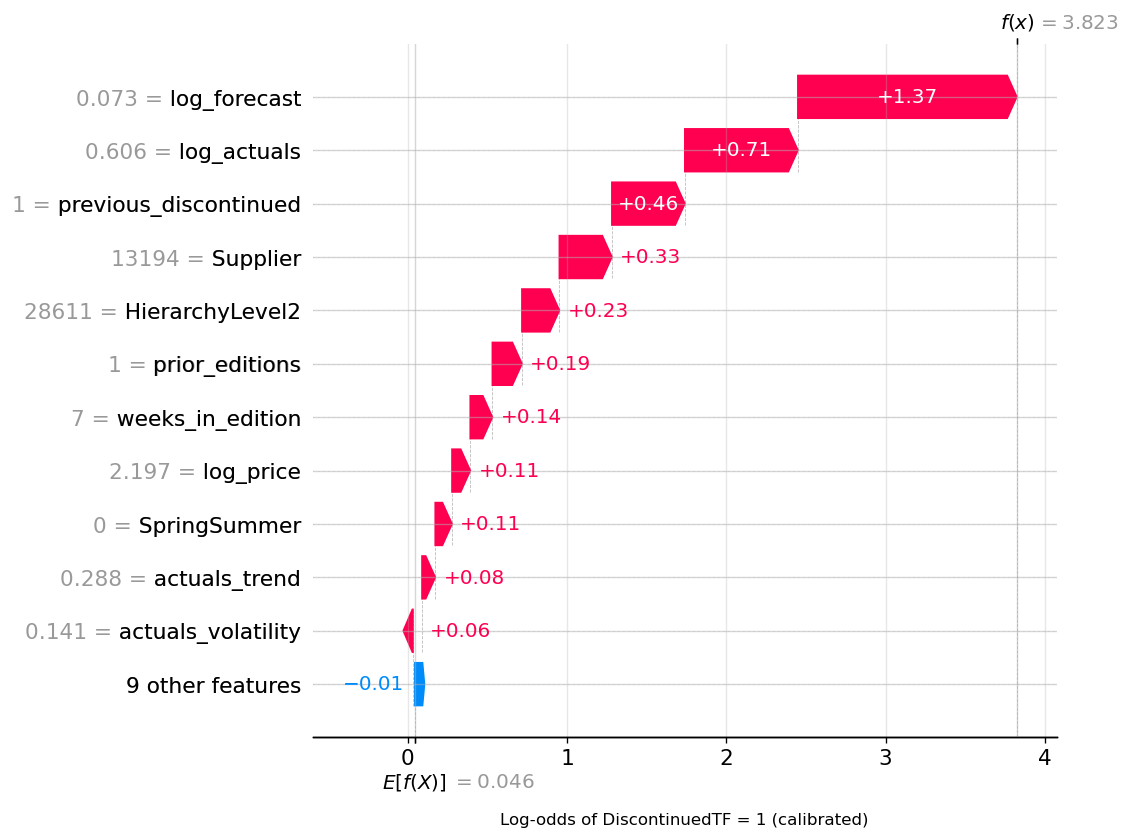

In [5]:
from io import BytesIO
from IPython.display import Image, display

figure = waterfall_figure(explanation)
buffer = BytesIO()
figure.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
plt.close(figure)
display(Image(buffer.getvalue(), width=620))

In [6]:
from product_discontinuation import narrative

raising, lowering = narrative.key_factors(explanation.contributions, bundle["reference_values"])
print(narrative.summary(top.probability, top.risk_category, bundle["threshold"], raising, lowering))

This product has an elevated chance of being discontinued at the next catalogue refresh (estimated 98%). This is above the 28% level at which products are flagged for review. The product's expected weekly sales and average weekly sales level contributed most to this result. Suggested next step: check whether the demand forecast for the remaining weeks is still realistic.


### Global behaviour and validation

The evidence below comes from 500 randomly chosen products in held-out edition 93. Using held-out rows here only describes the fixed model: no explanation result feeds back into training, tuning or the threshold.

In [7]:
import json
from IPython.display import Image, display

pd.read_csv(config.RESULTS_DIR / "shap_global_importance_h13.csv").round(4)

,feature,rank,mean_abs_shap,mean_shap,tree_path_dependent_mean_abs,permutation_importance_pr_auc
0,HierarchyLevel2,1,1.3350,-1.0763,1.2749,0.2876
1,log_actuals,2,0.3839,0.0726,0.3937,0.0168
2,log_forecast,3,0.2855,0.0434,0.3004,0.0328
3,prior_editions,4,0.2177,0.0263,0.1880,0.0152
4,HierarchyLevel1,5,0.1216,0.0028,0.1262,0.0136
5,SpringSummer,6,0.1041,-0.1041,0.0987,0.0000
6,log_price,7,0.0923,0.0029,0.0898,-0.0004
7,actuals_volatility,8,0.0888,-0.0036,0.0903,-0.0014
8,actuals_trend,9,0.0776,0.0103,0.0785,-0.0011
9,in_previous_edition,10,0.0766,0.0115,0.0473,0.0003


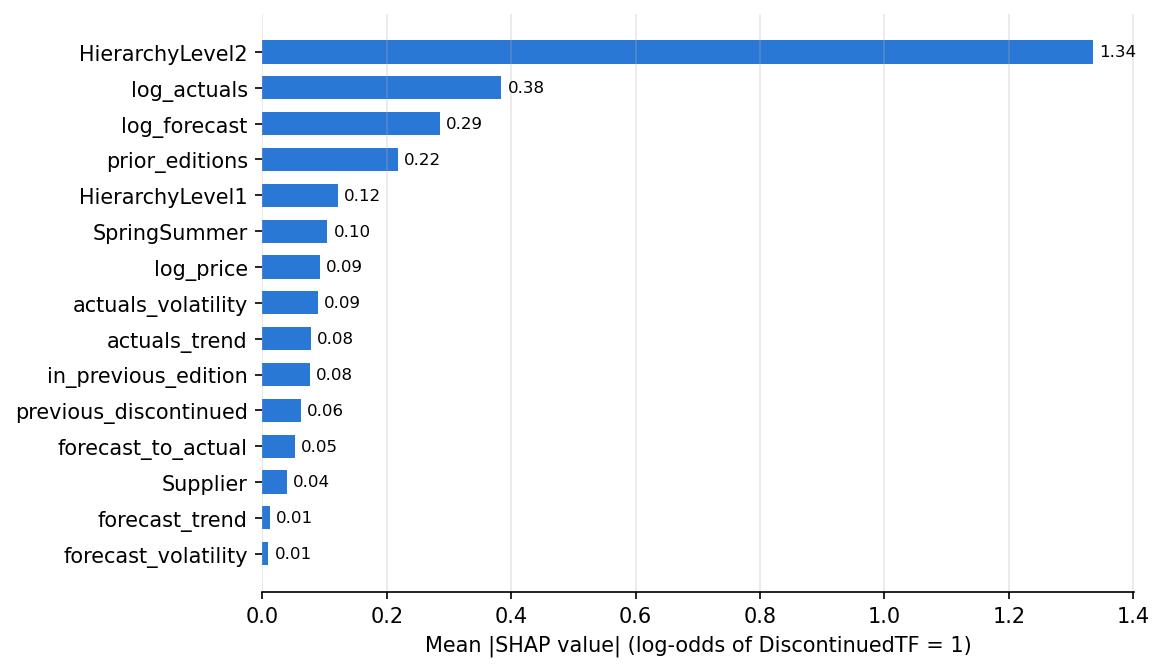

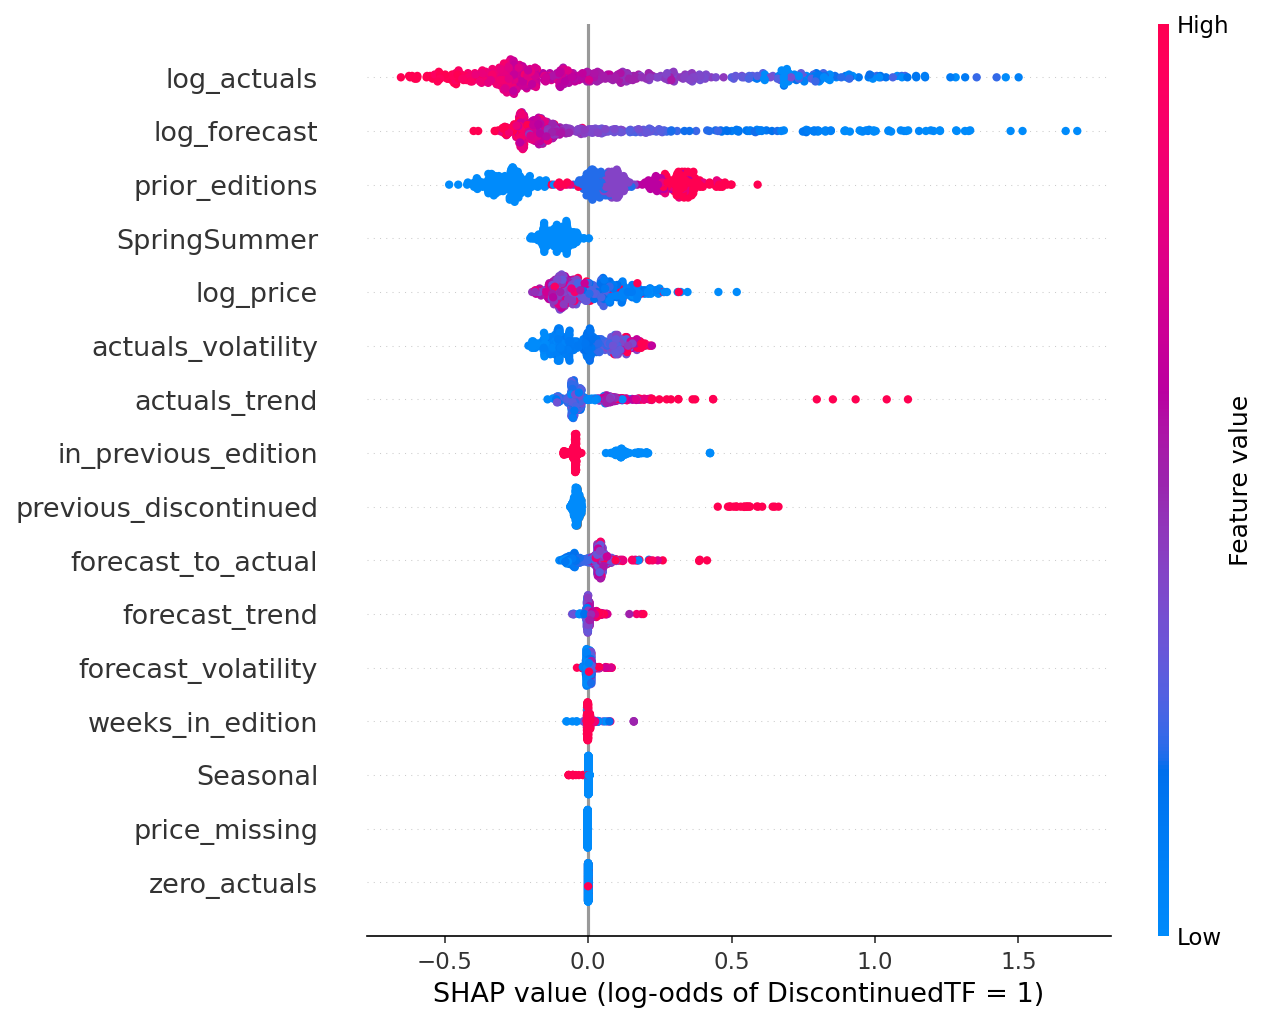

In [8]:
for name in ["shap_global_importance_h13.png", "shap_beeswarm_numeric_h13.png"]:
    display(Image(filename=str(config.FIGURES_DIR / name), width=620))

In [9]:
validation = json.loads((config.RESULTS_DIR / "shap_validation_h13.json").read_text())
{k: validation[k] for k in ["base_value_probability", "seconds_per_explanation", "max_local_accuracy_error_log_odds",
                            "max_difference_vs_saved_test_probabilities", "determinism_max_difference",
                            "convergence_vs_8000_evals", "alternative_background_seed_43",
                            "tree_path_dependent_cross_check", "interventional_tree_shap_check"]}

{'base_value_probability': 0.5114026493900928,
 'seconds_per_explanation': 1.213610341083986,
 'max_local_accuracy_error_log_odds': 1.7319479184152442e-14,
 'max_difference_vs_saved_test_probabilities': 0.0,
 'determinism_max_difference': 0.0,
 'convergence_vs_8000_evals': {'mean_abs_difference': 0.0009250246783282781,
  'p95_abs_difference': 0.0036309699295476662,
  'max_abs_difference': 0.01385343648505799,
  'top3_overlap': 1.0,
  'sign_agreement_on_meaningful': 1.0,
  'rows': 20,
  'seconds_per_explanation_at_8000': 8.818967327100108},
 'alternative_background_seed_43': {'mean_abs_difference': 0.011624605272589955,
  'p95_abs_difference': 0.049632553491564445,
  'max_abs_difference': 0.07286526484800482,
  'top3_overlap': 0.9666666666666666,
  'sign_agreement_on_meaningful': 1.0,
  'rows': 20,
  'base_value': -0.08586920065574864},
 'tree_path_dependent_cross_check': {'base_value': -0.09570832140996766,
  'max_additivity_error': 5.773159728050814e-15,
  'spearman_global_mean_abs': 

SHAP values describe how this model uses its inputs relative to the background; they are not causal effects. Independent masking can create unrealistic combinations of correlated inputs, since `forecast_to_actual` is the difference between `log_forecast` and `log_actuals`. TreeExplainer's path-dependent mode is used only as a cross-check and is rescaled to calibrated log-odds for comparison; its interventional mode fails the additivity check for this model in shap 0.49.1, as recorded above (that diagnostic alone is on the raw model scale).

### Additional check: feature-reset sensitivity (not SHAP)

In [10]:
top = live_preds.sort_values("probability", ascending=False).iloc[0]
row = live_features[live_features.ProductKey == top.ProductKey]
explain_prediction(bundle, row).head(8)

,feature,value,typical_value,effect
2,log_forecast,0.07325,4.000309,0.050032
14,HierarchyLevel2,28611,9740,0.049158
1,log_actuals,0.605954,3.751455,0.024378
6,previous_discontinued,1.0,0.0,0.009734
12,Supplier,13194,14733,0.005637
13,HierarchyLevel1,80445,67967,0.004714
4,weeks_in_edition,7,12.0,0.002845
10,actuals_trend,0.2875,0.0,0.002656


Each effect is the change in calibrated probability when one feature is reset to a typical training value (median or most frequent). This is a simple sensitivity check, separate from SHAP: it ignores interactions and is not used by the application.

## 3. Input drift (PSI) - live edition vs training data

In [11]:
drift = monitoring.feature_drift_report(bundle["drift_reference"], live_features)
drift.round(3)

,feature,psi,status
0,SpringSummer,4.763,significant
1,HierarchyLevel2,4.080,significant
2,prior_editions,1.478,significant
3,HierarchyLevel1,0.993,significant
4,Supplier,0.941,significant
5,actuals_trend,0.808,significant
6,forecast_trend,0.229,moderate
7,log_actuals,0.200,moderate
8,actuals_volatility,0.182,moderate
9,log_forecast,0.144,moderate


In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
d = drift.dropna().iloc[::-1]
ax.barh(d.feature, d.psi, color="#4C72B0")
ax.axvline(monitoring.PSI_MODERATE, color="grey", ls="--", lw=1, label="moderate (0.10)")
ax.axvline(monitoring.PSI_SIGNIFICANT, color="black", ls="--", lw=1, label="significant (0.25)")
ax.set(xlabel="Population Stability Index", title="Feature drift: live edition vs training"); ax.legend()
plt.show()

/var/folders/n5/l4mcv0vj2nvgwfffg4794gnw0000gn/T/ipykernel_13684/1475933912.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Interpret drift with domain knowledge:
- `SpringSummer` drift is expected - each edition is a single season.
- `prior_editions` rises over time because the data window starts at edition 88 (left-censoring).
- Hierarchy/Supplier drift reflects the genuine narrowing of the range (7 top-level categories in edition 94). Significant drift here means predictions for edition 94 should be treated with caution and is a trigger for retraining once edition 94's outcomes are known.

## 4. Prediction distribution drift

In [13]:
psi = monitoring.prediction_drift(bundle["reference_probabilities"], live_preds["probability"])
print(f"PSI of live calibrated probabilities vs test-edition predictions: {psi:.3f} ({monitoring.drift_status(psi)})")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(bundle["reference_probabilities"], bins=40, alpha=0.6, density=True, label="Test edition 93 (reference)")
ax.hist(live_preds.probability, bins=40, alpha=0.6, density=True, label="Live edition 94")
ax.axvline(bundle["threshold"], color="black", ls="--", lw=1, label="High from (calibrated threshold)")
ax.axvline(bundle["risk_medium_floor"], color="grey", ls=":", lw=1, label="Medium from (calibrated floor)")
ax.set(xlabel="Calibrated probability", ylabel="Density"); ax.legend(); plt.show()

PSI of live calibrated probabilities vs test-edition predictions: 0.149 (moderate)


/var/folders/n5/l4mcv0vj2nvgwfffg4794gnw0000gn/T/ipykernel_13684/881368768.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ax.set(xlabel="Calibrated probability", ylabel="Density"); ax.legend(); plt.show()


## 5. Performance monitoring needs labels
Accuracy cannot be measured for edition 94 until its refresh happens. Once outcomes arrive, `evaluate_against_outcomes` joins logged predictions to actual labels. The back-test below simulates this with edition 93, using calibrated probabilities and the calibrated threshold.

In [14]:
import json
summary_path = config.RESULTS_DIR / "monitoring_summary.json"
if summary_path.exists():
    summary = json.loads(summary_path.read_text())
    print(json.dumps(summary["backtest_outcome_monitoring"], indent=2))
else:
    print("Run: python -m product_discontinuation.monitor")

{
  "logged": 26783,
  "with_outcome": 26783,
  "label_coverage": 1.0,
  "metrics": {
    "threshold": 0.2825334577996326,
    "n": 26783,
    "positive_rate": 0.36388754060411455,
    "roc_auc": 0.9518194884707962,
    "pr_auc": 0.9146598721484012,
    "precision": 0.7469100896679861,
    "recall": 0.9486969012928381,
    "f1": 0.8357966101694915,
    "balanced_accuracy": 0.8824015116313342,
    "accuracy": 0.8643542545644626,
    "tn": 13904,
    "fp": 3133,
    "fn": 500,
    "tp": 9246
  }
}


In [15]:
log = monitoring.load_prediction_log()
print(len(log), "logged predictions")
log.groupby(["source", "model_version"]).size()

137869 logged predictions


source     model_version
backtest   1.0.0            26783
           1.1.0            26783
live       1.0.0            28101
           1.1.0            28101
streamlit  1.0.0            28101
dtype: int64

Rows logged by model version 1.0.0 contain raw scores and rows logged by 1.1.0 contain calibrated probabilities. The back-test above uses only the current version.